Лабораторна робота №4
# "Дослідження дерев рішень та ансамблевих методів у задачі багатокласової класифікації за наявності пропущених значень"

**Мета:** Дослідити та порівняти три алгоритми класифікації - дерево рішень (Decision Tree), випадковий ліс (Random Forest) та градієнтний бустинг (XGBoost) - на реальному датасеті Annealing, що містить пропущені значення. Основну увагу приділити:
- впливу способу обробки пропусків на якість класифікації;
- коректному (без витоку даних) підбору гіперпараметрів за допомогою Optuna;
- неупередженому оцінюванню моделей (вкладена крос-валідація) та статистичному порівнянню результатів;
- інтерпретації моделей і розбіжностей між їхніми прогнозами (permutation importance, SHAP). 

**Варіант №12**: <br>
SEED = 42 + 12 = **54**

**Використаний датасет**: Annealing <br>
Датасет Annealing описує параметри промислового процесу вiдпалу сталi. Його можна завантажити з OpenML:

```python
from sklearn.datasets import fetch_openml

data = fetch_openml(name='anneal', version=1, as_frame=True)
X, y = data.data, data.target
```

Основнi характеристики:
- кiлькiсть спостережень: 898 (OpenML) або 798 (навчальна частина в UCI) — у звiтi вказати, яку версiю використано;
- 38 ознак: числовi, бiнарнi та категорiальнi;
- цiльова змiнна: багатокласова, iз сильним дисбалансом — один клас домiнує, а найменший мiстить лише кiлька спостережень; один iз класiв описаних у документацiї, у даних вiдсутнiй;
- багато ознак мають дуже високу частку пропускiв, причому частина з них є структурними (див. документацiю датасету anneal.names).

## **Етап 1**. Первинний аналіз даних

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency
from sklearn.datasets import fetch_openml
from sklearn.preprocessing import LabelEncoder

SEED = 54  # 42 + N, N = 12
np.random.seed(SEED)

data = fetch_openml(name='anneal', version=1, as_frame=True)


In [2]:
X, y = data.data.copy(), data.target.copy()

# Переводимо category в object
cat_cols = X.select_dtypes('category').columns
X[cat_cols] = X[cat_cols].astype(object)
y = y.astype(str)

num_cols = X.select_dtypes('number').columns
cat_cols = X.select_dtypes(exclude='number').columns

print('Версія датасету: OpenML anneal v1')
print(f'Спостережень: {X.shape[0]}, ознак: {X.shape[1]}')
print(f'Числових: {len(num_cols)}, категоріальних: {len(cat_cols)}')
print('\nЧислові:', list(num_cols))
print('\nКатегоріальні:', list(cat_cols))

Версія датасету: OpenML anneal v1
Спостережень: 898, ознак: 38
Числових: 6, категоріальних: 32

Числові: ['carbon', 'hardness', 'strength', 'thick', 'width', 'len']

Категоріальні: ['family', 'product-type', 'steel', 'temper_rolling', 'condition', 'formability', 'non-ageing', 'surface-finish', 'surface-quality', 'enamelability', 'bc', 'bf', 'bt', 'bw%2Fme', 'bl', 'm', 'chrom', 'phos', 'cbond', 'marvi', 'exptl', 'ferro', 'corr', 'blue%2Fbright%2Fvarn%2Fclean', 'lustre', 'jurofm', 's', 'p', 'shape', 'oil', 'bore', 'packing']


Датасет OpenML anneal v1: 898 об'єктів, 38 ознак (6 числових, 32 категоріальних). Категоріальні приведено до object

,n_missing,pct_missing,n_unique,dtype
marvi,898,100.000000,0,object
s,898,100.000000,0,object
p,898,100.000000,0,object
corr,898,100.000000,0,object
jurofm,898,100.000000,0,object
m,898,100.000000,0,object
bc,897,99.888641,1,object
exptl,896,99.777283,1,object
blue%2Fbright%2Fvarn%2Fclean,892,99.331849,3,object
phos,891,99.220490,1,object


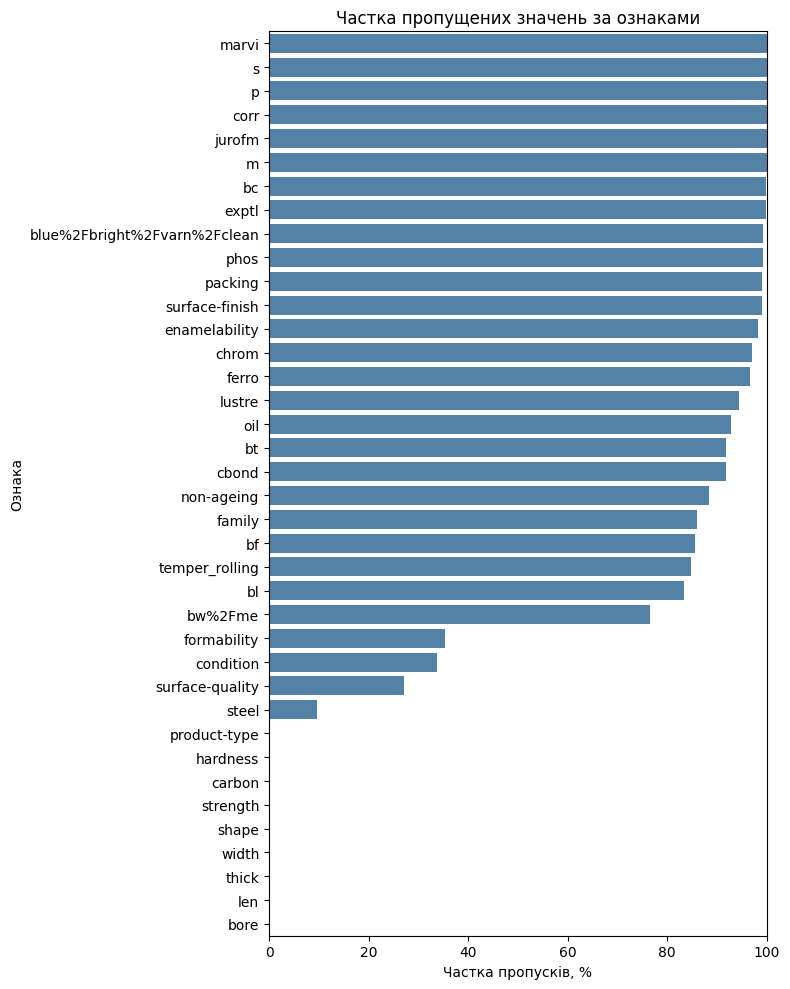

In [3]:
# Обчислення частки пропусків
miss = pd.DataFrame({
    'n_missing': X.isna().sum(),
    'pct_missing': X.isna().mean() * 100,
    'n_unique': X.nunique(dropna=True),
    'dtype': X.dtypes.astype(str),
}).sort_values('pct_missing', ascending=False)
display(miss)

fig, ax = plt.subplots(figsize=(8, 10))
sns.barplot(x='pct_missing', y=miss.index, data=miss, color='steelblue', ax=ax)
ax.set_xlabel('Частка пропусків, %')
ax.set_ylabel('Ознака')
ax.set_title('Частка пропущених значень за ознаками')
ax.set_xlim(0, 100)
plt.tight_layout()
plt.show()

Багато ознак мають частку пропусків понад 80%, 6 повністю порожні. Це свідчить про структурні пропуски

In [4]:
# Видалення порожніх і константних ознак
n_nonnull = X.notna().sum()
nuniq = X.nunique(dropna=True)

empty_cols = list(X.columns[n_nonnull == 0])
# константна = немає жодного пропуску І лише одне значення
const_cols = list(X.columns[(n_nonnull == len(X)) & (nuniq <= 1)])

print('Повністю порожні (100% пропусків):', empty_cols)
print('Константні без пропусків:', const_cols)

# Для інформації: ознаки з одним значенням + пропуски (структурні, ЗАЛИШАЄМО)
struct_cols = list(X.columns[(n_nonnull > 0) & (n_nonnull < len(X)) & (nuniq == 1)])
print('Структурні прапорці (одне значення + пропуски, залишаємо):', struct_cols)

dropped = empty_cols + const_cols
X = X.drop(columns=dropped)
print(f'\nВидалено {len(dropped)} ознак, залишилось {X.shape[1]}')

num_cols = X.select_dtypes('number').columns
cat_cols = X.select_dtypes(exclude='number').columns

Повністю порожні (100% пропусків): ['m', 'marvi', 'corr', 'jurofm', 's', 'p']
Константні без пропусків: ['product-type']
Структурні прапорці (одне значення + пропуски, залишаємо): ['temper_rolling', 'non-ageing', 'surface-finish', 'bc', 'bf', 'bt', 'bl', 'chrom', 'phos', 'cbond', 'exptl', 'ferro', 'lustre']

Видалено 7 ознак, залишилось 31


Видалено 6 повністю порожніх ознак (m, marvi, corr, jurofm, s, p): вони не містять жодного значення й не несуть інформації. Також видалено константну ознаку product-type без пропусків (усі значення 'C'). Ознаки, що мають одне значення та багато пропусків (bf, bt, bl, lustre та ін.), залишено навмисно: це структурні пропуски, де відсутність значення означає «характеристика не застосовна/відсутня», тому факт пропуску є інформативним, а індикатор пропуску у варіанті B несе сигнал. Рішення прийнято за самими ознаками, без використання цільової змінної.

class
3    684
2     99
5     67
U     40
1      8
Name: count, dtype: int64

Класи з документації, яких немає в даних: ['4']


,всього,train (80%),outer-train (5 блоків),inner-train (3 блоки),у тесті (20%)
class,,,,,
3,684,547.2,437.8,291.8,136.8
2,99,79.2,63.4,42.2,19.8
5,67,53.6,42.9,28.6,13.4
U,40,32.0,25.6,17.1,8.0
1,8,6.4,5.1,3.4,1.6


Мінімальний клас: 1 -> 8 об'єктів


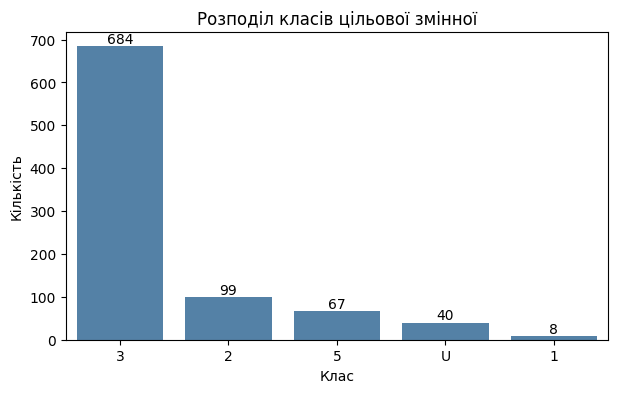

In [5]:
counts = y.value_counts()
print(counts)
print('\nКласи з документації, яких немає в даних:',
      sorted(set(['1', '2', '3', '4', '5', 'U']) - set(counts.index)))

# Скільки об'єктів кожного класу залишиться на різних рівнях розбиття
rep = pd.DataFrame({'всього': counts})
rep['train (80%)'] = (counts * 0.8).round(1)
rep['outer-train (5 блоків)'] = (counts * 0.8 * 0.8).round(1)
rep['inner-train (3 блоки)'] = (counts * 0.8 * 0.8 * 2 / 3).round(1)
rep['у тесті (20%)'] = (counts * 0.2).round(1)
display(rep)
print('Мінімальний клас:', counts.idxmin(), '->', counts.min(), 'об\'єктів')

fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(x=counts.index, y=counts.values, color='steelblue', ax=ax)
for i, v in enumerate(counts.values):
    ax.text(i, v, str(v), ha='center', va='bottom')
ax.set_xlabel('Клас')
ax.set_ylabel('Кількість')
ax.set_title('Розподіл класів цільової змінної')
plt.show()

Розподіл класів сильно незбалансований: домінує клас 3 (684 з 898 об'єктів), найменший клас 1 має лише 8; клас 4, описаний у документації, у даних відсутній. Усі п'ять наявних класів залишено без змін: об'єднання змінило б зміст задачі. Для класу 1 очікувана кількість об'єктів у тренувальній частині внутрішньої 3-блочної CV становить ≈3,4 (у гіршому разі 2), що достатньо для присутності класу в кожному блоці й для роботи XGBoost, тому внутрішня CV має саме 3 блоки. Через мізерну кількість об'єктів класу 1 у валідаційних блоках і в тесті (1–2) macro F1 буде дуже шумною: помилка на одному об'єкті помітно змінює F1 цього класу.

In [6]:
# Кодування цільової змінної
le = LabelEncoder()
y_enc = le.fit_transform(y)
print('Відповідність:', dict(zip(le.classes_, le.transform(le.classes_))))
print('K =', len(le.classes_), '| y_enc:', np.bincount(y_enc))

Відповідність: {'1': np.int64(0), '2': np.int64(1), '3': np.int64(2), '5': np.int64(3), 'U': np.int64(4)}
K = 5 | y_enc: [  8  99 684  67  40]


Цільову змінну закодовано як 0–4 (класи 1, 2, 3, 5, U); клас 4 відсутній у даних

In [7]:
# Статистика x2 для таблиці частот (рядки/стовпці з нульовою сумою пропускаються)
def chi2_stat(table):
    table = table[table.sum(1) > 0][:, table.sum(0) > 0]
    exp = np.outer(table.sum(1), table.sum(0)) / table.sum()
    return ((table - exp) ** 2 / exp).sum()

# Монте-Карло перестановочний тест незалежності
def mc_pvalue(m, yy, K, n_perm=10000, seed=SEED):
    rng = np.random.default_rng(seed)
    def tab(a, b):
        return np.bincount(a * K + b, minlength=2 * K).reshape(2, K).astype(float)
    obs = chi2_stat(tab(m, yy))
    perm = np.array([chi2_stat(tab(m, rng.permutation(yy))) for _ in range(n_perm)])
    return obs, (1 + (perm >= obs).sum()) / (n_perm + 1)

K = len(le.classes_)
frac = X.isna().mean()
top_feats = (frac.sort_values(ascending=False).head(5).index.tolist()      # найбільша частка пропусків
             + ['bf', 'bl', 'temper_rolling', 'non-ageing'])               # структурні, достатньо спостережень
top_feats = list(dict.fromkeys(top_feats))
rows = []

for f in top_feats:
    m = X[f].isna().astype(int).values
    ct = pd.crosstab(pd.Series(m, name='пропуск'),
                     pd.Series(le.inverse_transform(y_enc), name='клас'))
    print(f'\n=== {f}  (пропусків {m.mean()*100:.1f}%) ===')
    display(ct)
    display((pd.crosstab(pd.Series(m, name='пропуск'),
                         pd.Series(le.inverse_transform(y_enc), name='клас'),
                         normalize='columns') * 100).round(1)
            .loc[[1]].rename(index={1: '% пропусків у класі'}))

    if ct.shape[0] < 2:
        rows.append((f, np.nan, np.nan, 'немає варіації'))
        continue
    exp_min = chi2_contingency(ct)[3].min()
    if exp_min >= 5:
        chi2, p, dof, _ = chi2_contingency(ct)
        method = 'χ²'
    else:
        chi2, p = mc_pvalue(m, y_enc, K)
        method = 'Монте-Карло χ² (очікувані частоти <5)'
    rows.append((f, chi2, p, method))

res = pd.DataFrame(rows, columns=['ознака', 'χ²', 'p-value', 'метод'])
res['залежність від класу (α=0.05)'] = np.where(res['p-value'] < 0.05, 'так', 'ні')
display(res)


=== bc  (пропусків 99.9%) ===


клас,1,2,3,5,U
пропуск,,,,,
0,0,0,1,0,0
1,8,99,683,67,40


клас,1,2,3,5,U
пропуск,,,,,
% пропусків у класі,100.0,100.0,99.9,100.0,100.0



=== exptl  (пропусків 99.8%) ===


клас,1,2,3,5,U
пропуск,,,,,
0,2,0,0,0,0
1,6,99,684,67,40


...

клас,1,2,3,5,U
пропуск,,,,,
% пропусків у класі,87.5,100.0,85.7,100.0,5.0



=== non-ageing  (пропусків 88.3%) ===


клас,1,2,3,5,U
пропуск,,,,,
0,0,0,57,48,0
1,8,99,627,19,40


клас,1,2,3,5,U
пропуск,,,,,
% пропусків у класі,100.0,100.0,91.7,28.4,100.0


,ознака,χ²,p-value,метод,залежність від класу (α=0.05)
0,bc,0.313214,1.000000,Монте-Карло χ² (очікувані частоти <5),ні
1,exptl,222.996652,0.000100,Монте-Карло χ² (очікувані частоти <5),так
2,blue%2Fbright%2Fvarn%2Fclean,37.365354,0.001300,Монте-Карло χ² (очікувані частоти <5),так
3,phos,87.502990,0.000200,Монте-Карло χ² (очікувані частоти <5),так
4,packing,2.844296,0.441656,Монте-Карло χ² (очікувані частоти <5),ні
5,bf,32.229545,0.000300,Монте-Карло χ² (очікувані частоти <5),так
6,bl,27.071962,0.000200,Монте-Карло χ² (очікувані частоти <5),так
7,temper_rolling,227.131891,0.000100,Монте-Карло χ² (очікувані частоти <5),так
8,non-ageing,260.140970,0.000100,Монте-Карло χ² (очікувані частоти <5),так


Для 9 ознак (5 із найбільшою часткою пропусків і 4 структурні з достатньою кількістю спостережень) перевірено незалежність факту пропуску та класу. Через малі очікувані частоти (клас 1 має 8 об'єктів) використано Монте-Карло перестановочний χ² (10 000 перестановок), тому мінімально можливе p ≈ 1·10⁻⁴. Для 7 ознак із 9 (exptl, blue…, phos, bf, bl, temper_rolling, non-ageing) незалежність відхилено: p ≤ 0,0013, і всі вони лишаються значущими навіть із поправкою Бонфероні для 9 тестів (α = 0,05/9 ≈ 0,0056). Наприклад, temper_rolling пропущена у 5% об'єктів класу U проти понад 85% у класах 1, 2, 3, 5 (у клас 3 потрапляє 98 з 137 непропущених), а non-ageing пропущена лише в 28% об'єктів класу 5 проти ≥ 91,7% у класах 1, 2, 3 і U. <br>
Отже, пропуски не схожі на MCAR: факт пропуску пов'язаний із класом, а відсутність значення є структурною (характеристика не застосовна до виробу). Це припускає, що індикатори пропусків (варіант B) несуть інформацію про клас. Для bc і packing незалежність не відхилено, але це результат низької потужності: у них лише 1 і 9 непропущених значень. Він не доводить MCAR. За самими даними розрізнити MAR і MNAR неможливо.

## **Етап 2**. Подiл даних i пайплайн обробки

In [8]:
# A. Поділ і розміри класів

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y_enc, test_size=0.2, stratify=y_enc, random_state=SEED
)
print('train:', X_train.shape, '| test:', X_test.shape)
print(pd.DataFrame({
    'train': np.bincount(y_train),
    'test': np.bincount(y_test),
}, index=le.classes_))

train: (718, 31) | test: (180, 31)
   train  test
1      6     2
2     79    20
3    547   137
5     54    13
U     32     8


In [9]:
# B. Препроцесор і пайплайн

import warnings
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.impute import SimpleImputer, MissingIndicator
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

# Фолд може не містити жодного значення в рідкісній ознаці (напр. bc): це очікувано
warnings.filterwarnings('ignore', message='Skipping features without any observed values')

def build_preprocessor(with_indicators: bool) -> ColumnTransformer:
    transformers = [
        ('num', SimpleImputer(strategy='median'),
         make_column_selector(dtype_include='number')),
        ('cat', Pipeline([
            ('impute', SimpleImputer(strategy='most_frequent')),
            ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
        ]), make_column_selector(dtype_exclude='number')),
    ]
    if with_indicators:
        transformers.append(
            ('miss', MissingIndicator(features='missing-only'),
             make_column_selector()))
    return ColumnTransformer(transformers)

def make_model(name, params=None):
    params = params or {}
    if name == 'DT':
        return DecisionTreeClassifier(random_state=SEED, **params)
    if name == 'RF':
        return RandomForestClassifier(random_state=SEED, n_jobs=-1, **params)
    return XGBClassifier(random_state=SEED, n_jobs=-1,
                         eval_metric='mlogloss', **params)

def build_pipeline(name, with_indicators=True, params=None):
    return Pipeline([('prep', build_preprocessor(with_indicators)),
                     ('clf', make_model(name, params))])

In [10]:
# Крос-валідація з типовими параметрами
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate

scoring = {'acc': 'accuracy', 'f1m': 'f1_macro', 'bacc': 'balanced_accuracy'}
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)  # ОДИН cv для всіх

cv_results = {}   # (variant, model) -> результати; потрібні для тесту Наде–Бенжіо
for variant, with_ind in [('A', False), ('B', True)]:
    for name in ['DT', 'RF', 'XGB']:
        cv_results[(variant, name)] = cross_validate(
            build_pipeline(name, with_indicators=with_ind),
            X_train, y_train, cv=cv, scoring=scoring)

def summary(variant):
    rows = {}
    for name in ['DT', 'RF', 'XGB']:
        r = cv_results[(variant, name)]
        rows[name] = {m: f"{r['test_'+m].mean():.4f} ± {r['test_'+m].std():.4f}"
                      for m in ['acc', 'f1m', 'bacc']}
    return pd.DataFrame(rows).T.rename(columns={
        'acc': 'Accuracy', 'f1m': 'Macro F1', 'bacc': 'Balanced acc.'})

print('Таблиця 1. Варіант A (імпутація), типові параметри'); display(summary('A'))
print('Таблиця 2. Варіант B (імпутація + індикатори), типові параметри'); display(summary('B'))

Таблиця 1. Варіант A (імпутація), типові параметри


,Accuracy,Macro F1,Balanced acc.
DT,0.9471 ± 0.0129,0.8786 ± 0.0827,0.8825 ± 0.0871
RF,0.9531 ± 0.0131,0.9222 ± 0.0491,0.9238 ± 0.0559
XGB,0.9536 ± 0.0122,0.8940 ± 0.0752,0.8851 ± 0.0785


Таблиця 2. Варіант B (імпутація + індикатори), типові параметри


,Accuracy,Macro F1,Balanced acc.
DT,0.9875 ± 0.0092,0.9592 ± 0.0523,0.9556 ± 0.0558
RF,0.9921 ± 0.0071,0.9672 ± 0.0509,0.9639 ± 0.0549
XGB,0.9879 ± 0.0086,0.9635 ± 0.0521,0.9603 ± 0.0553


Табл. 1–2. Додавання індикаторів пропусків (варіант B) суттєво покращує якість усіх трьох моделей: macro F1 зростає з 0,88/0,92/0,89 до 0,96/0,97/0,96 (DT/RF/XGB), accuracy – з ≈0,95 до ≈0,99. Це узгоджується з аналізом механізму пропусків: пропуски структурні й пов'язані з класом, а імпутація модою/медіаною стирає цю інформацію. Різниці між моделями всередині варіанта B (≈0,01) значно менші за стандартне відхилення (≈0,05), яке великою мірою зумовлене класом 1 із 1–2 об'єктами у валідаційному блоці, тому висновки про перевагу однієї моделі потребують статистичної перевірки.

In [11]:
# Перевірка, що фолди однакові
folds_a = [(tuple(a), tuple(b)) for a, b in cv.split(X_train, y_train)]
folds_b = [(tuple(a), tuple(b)) for a, b in cv.split(X_train, y_train)]
print('Блоки відтворюються однаково:', folds_a == folds_b, '| кількість блоків:', len(folds_a))

Блоки відтворюються однаково: True | кількість блоків: 15


## **Етап 3**. Optuna і вкладена CV

In [12]:
import optuna
import time
from sklearn.model_selection import StratifiedKFold, cross_val_score
optuna.logging.set_verbosity(optuna.logging.WARNING)

N_TRIALS = 30

def suggest_params(trial, name):
    if name == 'DT':
        return {
            'max_depth': trial.suggest_int('max_depth', 2, 20),
            'min_samples_split': trial.suggest_int('min_samples_split', 2, 20),
            'min_samples_leaf': trial.suggest_int('min_samples_leaf', 1, 10),
            'class_weight': trial.suggest_categorical('class_weight', [None, 'balanced']),
        }
    if name == 'RF':
        return {
            'n_estimators': trial.suggest_int('n_estimators', 100, 500, step=50),
            'max_depth': trial.suggest_int('max_depth', 3, 30),
            'min_samples_leaf': trial.suggest_int('min_samples_leaf', 1, 10),
            'max_features': trial.suggest_categorical('max_features', ['sqrt', 'log2', 0.5]),
            'class_weight': trial.suggest_categorical(
                'class_weight', [None, 'balanced', 'balanced_subsample']),
        }
    return {  # XGB
        'n_estimators': trial.suggest_int('n_estimators', 50, 400),
        'max_depth': trial.suggest_int('max_depth', 2, 10),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'subsample': trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
        'min_child_weight': trial.suggest_float('min_child_weight', 1, 10, log=True),
    }

def tune(name, X_tr, y_tr, n_trials=N_TRIALS):
    inner = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
    def objective(trial):
        # Передаємо ВЕСЬ пайплайн (імпутація + модель) -> без витоку
        pipe = build_pipeline(name, True, suggest_params(trial, name))
        return cross_val_score(pipe, X_tr, y_tr, cv=inner, scoring='f1_macro').mean()
    study = optuna.create_study(direction='maximize',
                                sampler=optuna.samplers.TPESampler(seed=SEED))
    study.optimize(objective, n_trials=n_trials)
    return study

c:\Users\svitj\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [13]:
# Оптимізація на всій train-вибірці (дає best_value і фінальні параметри)
studies = {}
for name in ['DT', 'RF', 'XGB']:
    t0 = time.time()
    studies[name] = tune(name, X_train, y_train)
    print(f'{name}: best_value = {studies[name].best_value:.4f}  '
          f'({time.time()-t0:.0f} с)')

DT: best_value = 0.9451  (2 с)
RF: best_value = 0.9625  (32 с)
XGB: best_value = 0.9610  (15 с)


In [14]:
# Вкладена крос-валідація
from sklearn.metrics import f1_score

outer = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
nested_scores = {}

for name in ['DT', 'RF', 'XGB']:
    t0 = time.time()
    scores = []
    for tr_idx, va_idx in outer.split(X_train, y_train):
        X_tr, y_tr = X_train.iloc[tr_idx], y_train[tr_idx]
        X_va, y_va = X_train.iloc[va_idx], y_train[va_idx]
        study = tune(name, X_tr, y_tr)
        model = build_pipeline(name, True, study.best_params).fit(X_tr, y_tr)
        scores.append(f1_score(y_va, model.predict(X_va), average='macro'))
    nested_scores[name] = np.array(scores)
    print(f'{name}: nested F1 per fold = {np.round(scores, 3)}  ({time.time()-t0:.0f} с)')

DT: nested F1 per fold = [0.981 0.792 0.833 0.932 1.   ]  (9 с)
RF: nested F1 per fold = [0.984 0.799 0.86  0.932 1.   ]  (161 с)
XGB: nested F1 per fold = [0.981 0.792 0.896 1.    0.993]  (66 с)


Таблиця 3. Вкладена CV (варіант B, після оптимізації)


,Nested CV macro F1,study.best_value,best_value − nested
DT,0.9076 ± 0.0819,0.9451,+0.0375
RF,0.9150 ± 0.0758,0.9625,+0.0475
XGB,0.9323 ± 0.0796,0.9610,+0.0287


Таблиця 4. Найкращі гіперпараметри (Optuna)


C:\Users\svitj\AppData\Local\Temp\ipykernel_210676\541796244.py:15: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  for n in studies}).T.fillna('—'))


,max_depth,min_samples_split,min_samples_leaf,class_weight,n_estimators,max_features,learning_rate,subsample,colsample_bytree,min_child_weight
DT,8.0,4,1,None,—,—,—,—,—,—
RF,9.0,—,1,None,150,0.5,—,—,—,—
XGB,10.0,—,—,—,182.0,—,0.187128,0.995352,0.721332,1.643055


C:\Users\svitj\AppData\Local\Temp\ipykernel_210676\541796244.py:24: ExperimentalWarning: optuna.visualization.matplotlib._optimization_history.plot_optimization_history is experimental (supported from v2.2.0). The interface can change in the future.
  ax = ovm.plot_optimization_history(studies[n]);


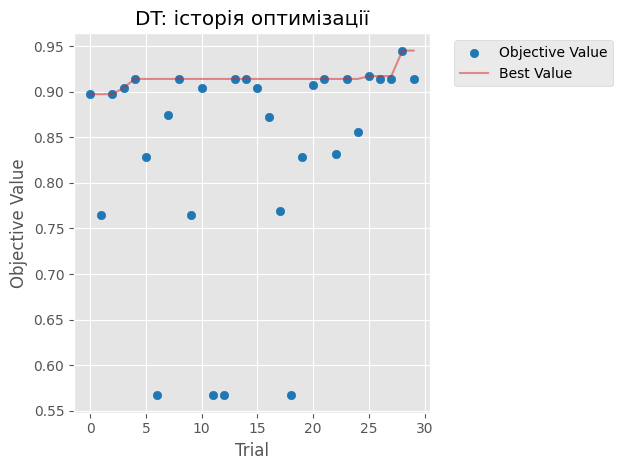

C:\Users\svitj\AppData\Local\Temp\ipykernel_210676\541796244.py:30: ExperimentalWarning: optuna.visualization.matplotlib._param_importances.plot_param_importances is experimental (supported from v2.2.0). The interface can change in the future.
  ax = ovm.plot_param_importances(studies[n]);


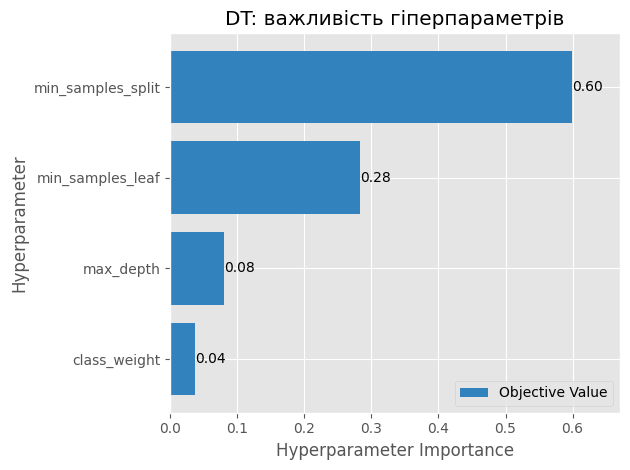

C:\Users\svitj\AppData\Local\Temp\ipykernel_210676\541796244.py:24: ExperimentalWarning: optuna.visualization.matplotlib._optimization_history.plot_optimization_history is experimental (supported from v2.2.0). The interface can change in the future.
  ax = ovm.plot_optimization_history(studies[n]);


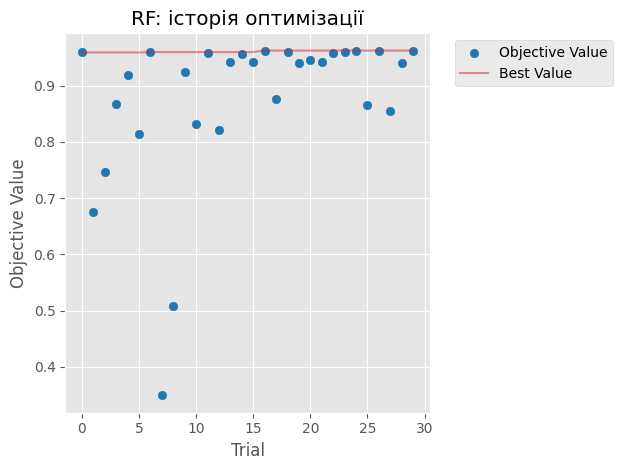

C:\Users\svitj\AppData\Local\Temp\ipykernel_210676\541796244.py:30: ExperimentalWarning: optuna.visualization.matplotlib._param_importances.plot_param_importances is experimental (supported from v2.2.0). The interface can change in the future.
  ax = ovm.plot_param_importances(studies[n]);


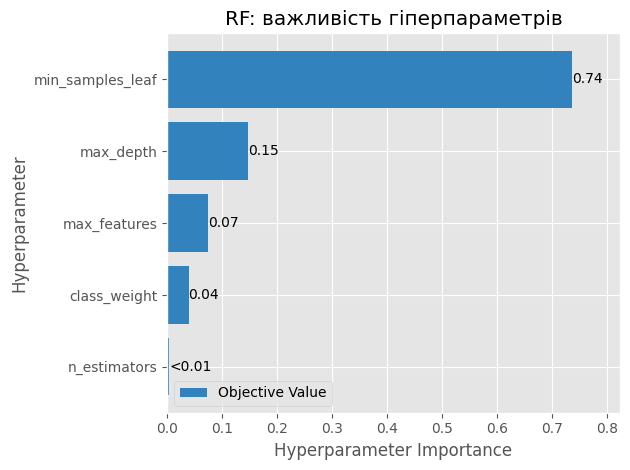

C:\Users\svitj\AppData\Local\Temp\ipykernel_210676\541796244.py:24: ExperimentalWarning: optuna.visualization.matplotlib._optimization_history.plot_optimization_history is experimental (supported from v2.2.0). The interface can change in the future.
  ax = ovm.plot_optimization_history(studies[n]);


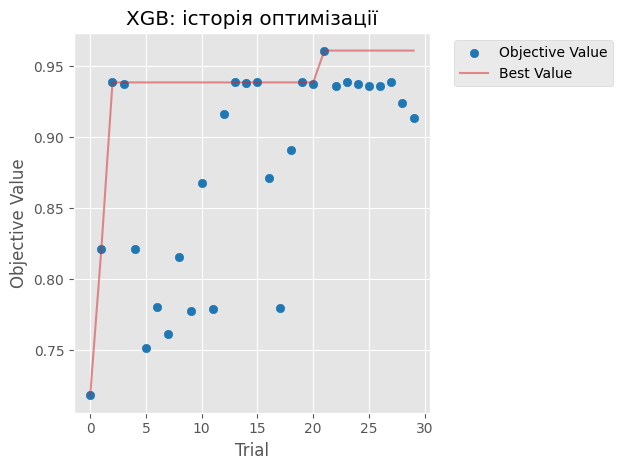

C:\Users\svitj\AppData\Local\Temp\ipykernel_210676\541796244.py:30: ExperimentalWarning: optuna.visualization.matplotlib._param_importances.plot_param_importances is experimental (supported from v2.2.0). The interface can change in the future.
  ax = ovm.plot_param_importances(studies[n]);


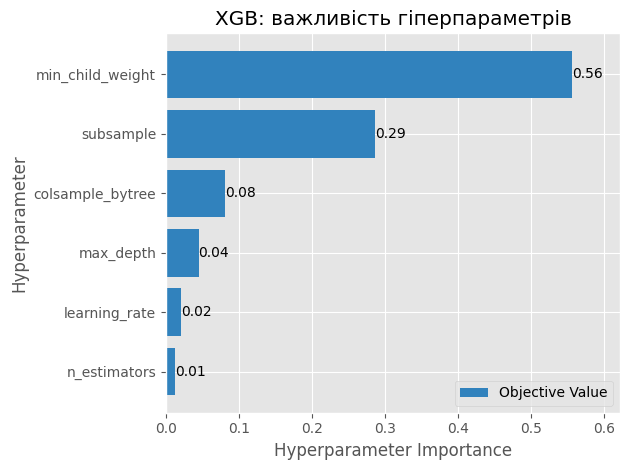

In [15]:
import optuna.visualization.matplotlib as ovm

# Таблиця 3
t3 = pd.DataFrame({
    name: {
        'Nested CV macro F1': f"{nested_scores[name].mean():.4f} ± {nested_scores[name].std():.4f}",
        'study.best_value':   f"{studies[name].best_value:.4f}",
        'best_value − nested': f"{studies[name].best_value - nested_scores[name].mean():+.4f}",
    } for name in studies}).T
print('Таблиця 3. Вкладена CV (варіант B, після оптимізації)'); display(t3)

# Таблиця 4
t4 = (pd.DataFrame({n: {k: ('None' if v is None else v)
                        for k, v in studies[n].best_params.items()}
                    for n in studies}).T.fillna('—'))
print('Таблиця 4. Найкращі гіперпараметри (Optuna)'); display(t4)

# Фінальні моделі на всій train-вибірці
final_models = {n: build_pipeline(n, True, studies[n].best_params).fit(X_train, y_train)
                for n in studies}

# Графіки: історія оптимізації та важливість гіперпараметрів
for n in studies:
    ax = ovm.plot_optimization_history(studies[n]); 
    for loc in ('left', 'center', 'right'):
            ax.set_title('', loc=loc)
    ax.set_title(f'{n}: історія оптимізації')
    plt.show()
    
    ax = ovm.plot_param_importances(studies[n]); 
    for loc in ('left', 'center', 'right'):
        ax.set_title('', loc=loc)
    ax.set_title(f'{n}: важливість гіперпараметрів')
    plt.tight_layout(); plt.show()

Табл. 3. best_value перевищує оцінку вкладеної CV на 0,029–0,048 (DT +0,038, RF +0,048, XGB +0,029): вибір максимуму серед 30 шумних оцінок дає оптимістично зміщену оцінку, тому best_value не можна подавати як якість моделі. Змінився й рейтинг: за best_value найкращий RF, за вкладеною CV XGB, проте стандартні відхилення (≈0,08, значною мірою через клас 1 із 1–2 об'єктами в блоці) перевищують різниці між моделями.

Табл. 4. Для DT знайдено max_depth=8, min_samples_split=4, min_samples_leaf=1; для RF max_depth=9, n_estimators=150, max_features=0,5, min_samples_leaf=1; для XGB max_depth=10 (верхня межа простору), n_estimators=182, learning_rate≈0,19. Для DT і RF найкращим виявився class_weight=None.

Графіки Optuna. Оптимізація XGB збіглась за ≈20 trial, для RF значення практично не змінювалось (≈0,96 від самого початку), для DT найкращий результат знайдено лише на 28-му trial. Найважливішими виявилися параметри, що задають мінімальний розмір листка й регуляризацію (min_samples_split/min_samples_leaf для DT, min_samples_leaf для RF, min_child_weight та subsample для XGB), а n_estimators і learning_rate майже не впливають. Імовірне пояснення: великі листки не дозволяють виділити найменший клас.

In [16]:
default_scores = {}
for name in ['DT', 'RF', 'XGB']:
    sc = []
    for tr_idx, va_idx in outer.split(X_train, y_train):
        m = build_pipeline(name, True).fit(X_train.iloc[tr_idx], y_train[tr_idx])
        sc.append(f1_score(y_train[va_idx], m.predict(X_train.iloc[va_idx]), average='macro'))
    default_scores[name] = np.array(sc)

gain = pd.DataFrame({n: {
    'типові параметри (ті ж 5 блоків)': f"{default_scores[n].mean():.4f} ± {default_scores[n].std():.4f}",
    'після оптимізації (nested)': f"{nested_scores[n].mean():.4f} ± {nested_scores[n].std():.4f}",
    'приріст': f"{nested_scores[n].mean() - default_scores[n].mean():+.4f}",
} for n in nested_scores}).T
display(gain)

,типові параметри (ті ж 5 блоків),після оптимізації (nested),приріст
DT,0.9402 ± 0.0779,0.9076 ± 0.0819,-0.0326
RF,0.9538 ± 0.0782,0.9150 ± 0.0758,-0.0388
XGB,0.9481 ± 0.0793,0.9323 ± 0.0796,-0.0158


Для всіх трьох моделей оптимізація гіперпараметрів не покращила, а погіршила nested-оцінку macro F1 відносно типових параметрів на тих самих зовнішніх блоках: DT −0,033, RF −0,039, XGB −0,016. Найменшу втрату має XGB, найбільшу - RF. 

Імовірні причини: внутрішня 3-блочна CV надзвичайно шумна через клас 1 (2–3 об'єкти в навчанні, 1–2 у валідації), тому TPE обирає параметри, що виграли за рахунок випадковості; типові параметри (необмежена глибина, min_samples_leaf=1) уже добре підходять для виділення малих класів, а знайдені обмеження глибини їх трохи погіршують. Різниці (≈0,02–0,04) менші за стандартне відхилення по блоках (≈0,08), тож на 5 блоках їх не можна вважати значущими. Цей результат демонструє, що тюнінг не гарантує покращення, а best_value взагалі не є оцінкою якості.

## **Етап 4**. Тест Наде–Бенжіо

In [17]:
from scipy import stats

def nadeau_bengio(d, ratio=1/4):
    d = np.asarray(d, float); k = len(d)
    mean, var = d.mean(), d.var(ddof=1)
    if var == 0:
        return mean, (0.0 if mean == 0 else np.inf), (1.0 if mean == 0 else 0.0)
    t = mean / np.sqrt(var * (1/k + ratio))
    return mean, t, 2 * stats.t.sf(abs(t), k - 1)

def row(label, d):
    mean, t, p = nadeau_bengio(d)
    return {'порівняння': label, 'd̄': round(mean, 4), 't': round(t, 3),
            'p': round(p, 4), 'висновок (α=0.05)': 'значуща' if p < 0.05 else 'незначуща'}

rows = [row(f'{n}: B − A', cv_results[('B', n)]['test_f1m'] - cv_results[('A', n)]['test_f1m'])
        for n in ['DT', 'RF', 'XGB']]
best2 = sorted(['DT', 'RF', 'XGB'],
               key=lambda n: cv_results[('B', n)]['test_f1m'].mean(), reverse=True)[:2]
rows.append(row(f'B: {best2[0]} − {best2[1]}',
                cv_results[('B', best2[0])]['test_f1m'] - cv_results[('B', best2[1])]['test_f1m']))
print('Таблиця 5. Скоригований t-тест Наде–Бенжіо (macro F1, 5×3 CV, df = 14)')
display(pd.DataFrame(rows))

Таблиця 5. Скоригований t-тест Наде–Бенжіо (macro F1, 5×3 CV, df = 14)


,порівняння,d̄,t,p,висновок (α=0.05)
0,DT: B − A,0.0806,2.007,0.0644,незначуща
1,RF: B − A,0.0449,4.143,0.0010,значуща
2,XGB: B − A,0.0695,1.792,0.0948,незначуща
3,B: RF − XGB,0.0037,0.936,0.3650,незначуща


Індикатори пропусків покращують macro F1 усіх моделей (+0,045…+0,081), але статистично значущою за скоригованим тестом Наде–Бенжіо (α = 0,05) є лише різниця для RF (p = 0,001, значуща й після поправки Бонфероні для 4 тестів). Для DT (p = 0,064) і XGB (p = 0,095) різниця незначуща, проте тест консервативний: поправка 1/(k·r) + n_test/n_train збільшує дисперсію статистики майже в 4,75 раза, а розкид різниць між блоками великий через клас 1. Між двома найкращими моделями у варіанті B (RF і XGB) значущої різниці немає (p = 0,365): в умовах ефекту стелі їх macro F1 статистично не відрізняються.

## **Етап 5**. Тест, матриця плутанини

Таблиця 6. Фінальні моделі (варіант B, після оптимізації) на тесті


,Accuracy,Macro F1,Balanced acc.
DT,1.0000,1.0000,1.0000
RF,0.9944,0.9859,0.9750
XGB,0.9833,0.9129,0.8735


Найкраща модель за nested CV: XGB
              precision    recall  f1-score   support

      клас 1       1.00      0.50      0.67         2
      клас 2       0.95      1.00      0.98        20
      клас 3       0.99      0.99      0.99       137
      клас 5       1.00      1.00      1.00        13
      клас U       1.00      0.88      0.93         8

    accuracy                           0.98       180
   macro avg       0.99      0.87      0.91       180
weighted avg       0.98      0.98      0.98       180



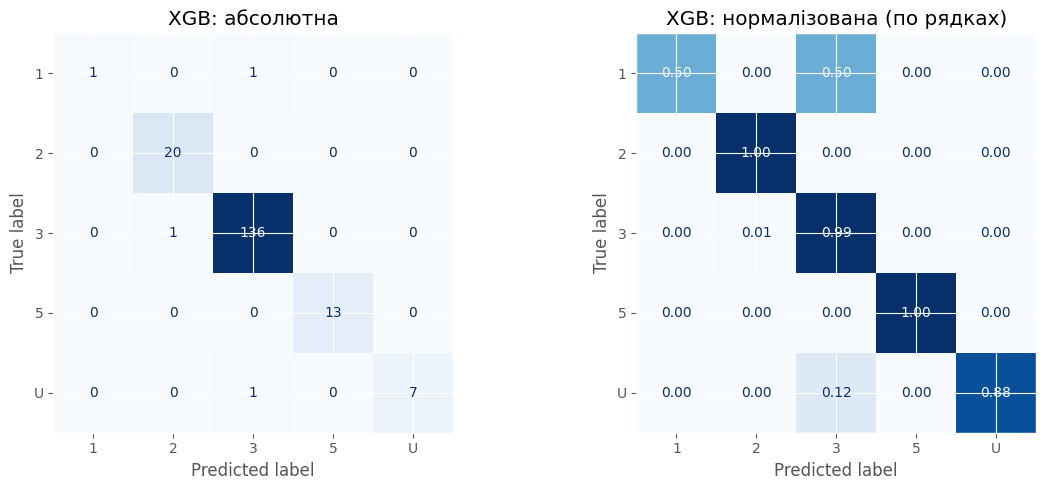

Помилки (справжній → передбачений, к-сть): [('1', '3', 1), ('3', '2', 1), ('U', '3', 1)]


In [18]:
from sklearn.metrics import (accuracy_score, f1_score, balanced_accuracy_score,
                             classification_report, confusion_matrix,
                             ConfusionMatrixDisplay)

# Таблиця 6
test_pred, rows6 = {}, {}
for n, m in final_models.items():
    p = m.predict(X_test); test_pred[n] = p
    rows6[n] = {'Accuracy': accuracy_score(y_test, p),
                'Macro F1': f1_score(y_test, p, average='macro'),
                'Balanced acc.': balanced_accuracy_score(y_test, p)}
print('Таблиця 6. Фінальні моделі (варіант B, після оптимізації) на тесті')
display(pd.DataFrame(rows6).T.round(4))

# Найкраща модель — за nested CV
best_name = max(nested_scores, key=lambda n: nested_scores[n].mean())
print('Найкраща модель за nested CV:', best_name)
print(classification_report(y_test, test_pred[best_name], labels=range(K),
      target_names=[f'клас {c}' for c in le.classes_], zero_division=0))

# Матриці плутанини
cm = confusion_matrix(y_test, test_pred[best_name], labels=range(K))
cm_n = confusion_matrix(y_test, test_pred[best_name], labels=range(K), normalize='true')
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
ConfusionMatrixDisplay(cm, display_labels=le.classes_).plot(
    ax=axes[0], cmap='Blues', colorbar=False)
axes[0].set_title(f'{best_name}: абсолютна')
ConfusionMatrixDisplay(cm_n, display_labels=le.classes_).plot(
    ax=axes[1], cmap='Blues', colorbar=False, values_format='.2f')
axes[1].set_title(f'{best_name}: нормалізована (по рядках)')
plt.tight_layout(); plt.show()

# Найчастіші помилки: (справжній, передбачений, кількість)
off = [(le.classes_[i], le.classes_[j], int(cm[i, j]))
       for i in range(K) for j in range(K) if i != j and cm[i, j] > 0]
print('Помилки (справжній → передбачений, к-сть):', sorted(off, key=lambda t: -t[2]))

Табл. 6. На тестовій вибірці (180 об'єктів) усі моделі мають accuracy ≥ 0,98, але macro F1 помітно відрізняється: DT 1,000, RF 0,986, XGB 0,913. Порядок протилежний до вкладеної CV (XGB найкращий, DT найгірший), що пояснюється малою кількістю об'єктів найменших класів у тесті: клас 1 має 2 об'єкти, клас U 8, тому одна помилка змінює F1 цього класу на 0,33–0,5 і macro F1 на ≈0,07. Різницю між моделями на тесті утворюють 1–3 об'єкти, тож вона статистично незначуща й не суперечить результатам CV, а лише демонструє шумність macro F1 при малих класах. Найкращою за nested CV обрано XGB: він помилився на 3 об'єктах (клас 1 → 3, клас 3 → 2, клас U → 3), тобто малі класи 1 і U плутаються з домінуючим класом 3 (recall класу 1 = 0,50, класу U = 0,88).

## **Етап 6**. Важливість ознак

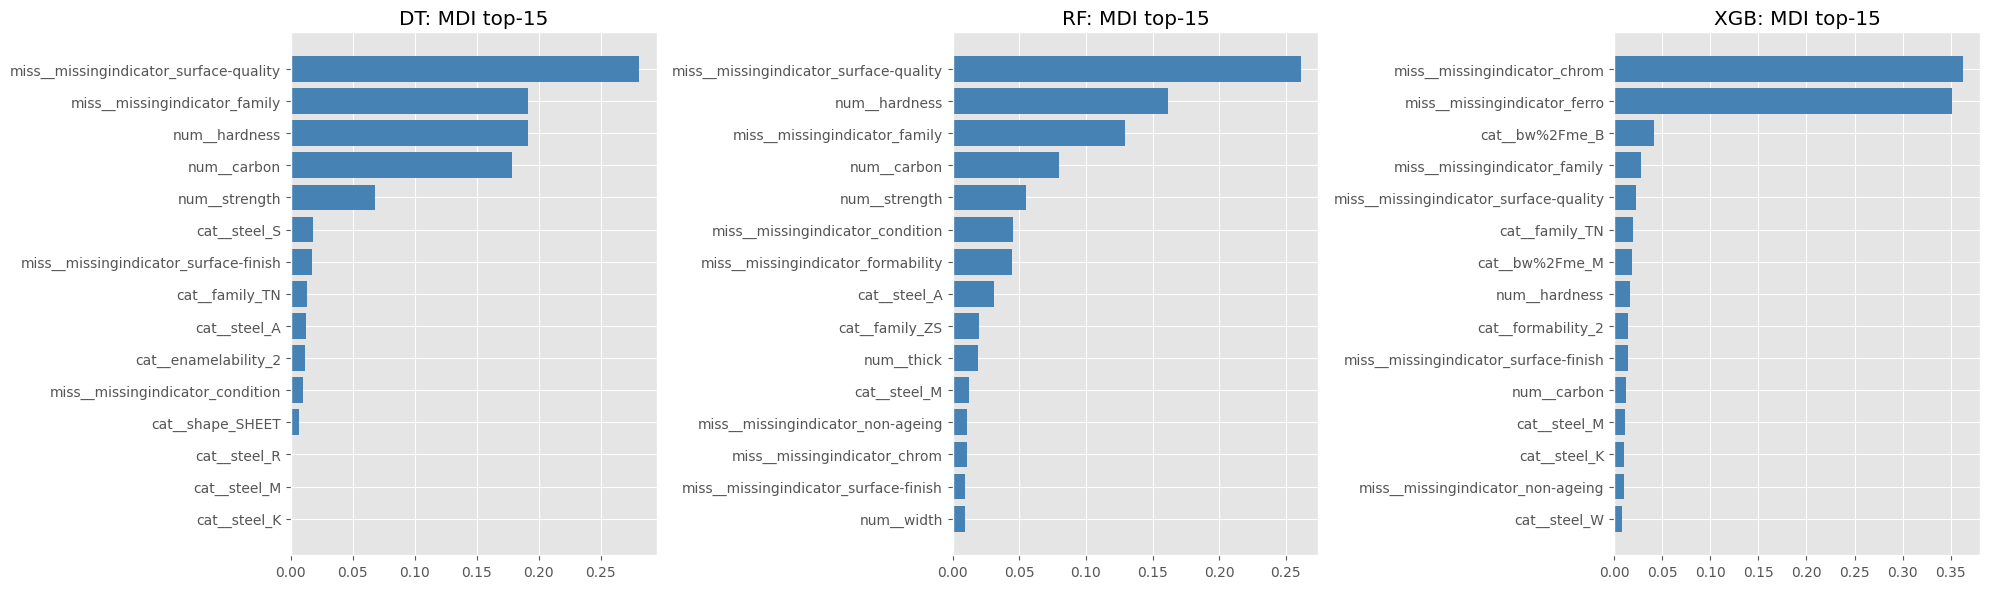

DT: індикаторів у top-15: 4/15 -> ['miss__missingindicator_surface-quality', 'miss__missingindicator_family', 'miss__missingindicator_surface-finish', 'miss__missingindicator_condition']
RF: індикаторів у top-15: 7/15 -> ['miss__missingindicator_surface-quality', 'miss__missingindicator_family', 'miss__missingindicator_condition', 'miss__missingindicator_formability', 'miss__missingindicator_non-ageing', 'miss__missingindicator_chrom', 'miss__missingindicator_surface-finish']
XGB: індикаторів у top-15: 6/15 -> ['miss__missingindicator_chrom', 'miss__missingindicator_ferro', 'miss__missingindicator_family', 'miss__missingindicator_surface-quality', 'miss__missingindicator_surface-finish', 'miss__missingindicator_non-ageing']


In [19]:
# MDI на оброблених ознаках (після one-hot, з індикаторами)
mdi = {}
for n, m in final_models.items():
    names = m.named_steps['prep'].get_feature_names_out()
    imp = m.named_steps['clf'].feature_importances_   # для XGB — gain, не чистий MDI
    mdi[n] = pd.Series(imp, index=names).sort_values(ascending=False)

fig, axes = plt.subplots(1, 3, figsize=(20, 6))
for ax, n in zip(axes, mdi):
    top = mdi[n].head(15)[::-1]
    ax.barh(top.index, top.values, color='steelblue')
    ax.set_title(f'{n}: MDI top-15')
plt.tight_layout(); plt.show()

for n in mdi:
    top = mdi[n].head(15).index
    k = sum('missingindicator' in f for f in top)
    print(f'{n}: індикаторів у top-15: {k}/15 ->',
          [f for f in top if 'missingindicator' in f])

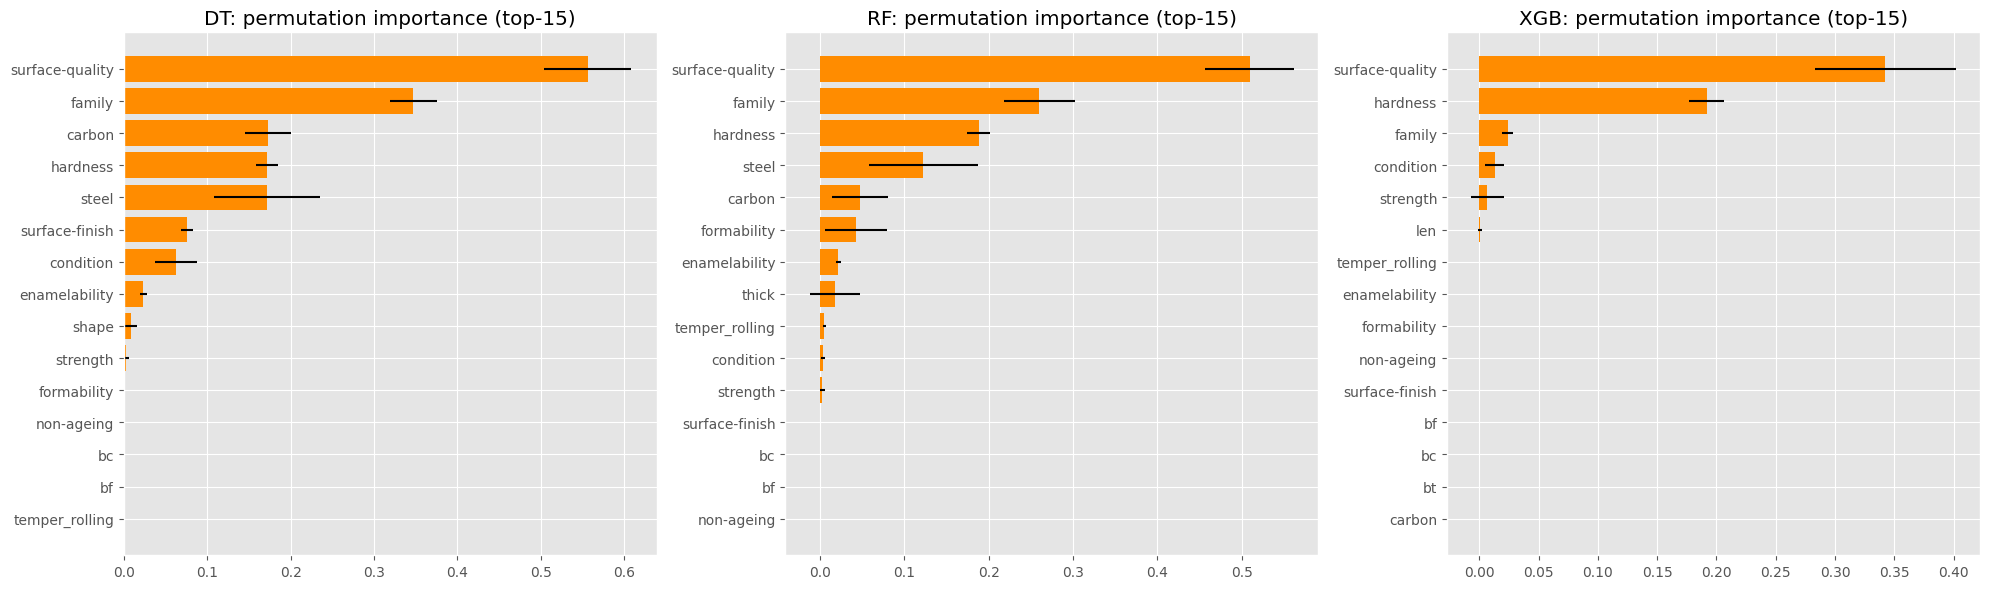

DT: Spearman(MDI агрегований, permutation) = 0.99 (p=0.000)
RF: Spearman(MDI агрегований, permutation) = 0.81 (p=0.000)
XGB: Spearman(MDI агрегований, permutation) = 0.23 (p=0.213)


In [20]:
from sklearn.inspection import permutation_importance
from scipy.stats import spearmanr

perm = {}
for n, m in final_models.items():
    r = permutation_importance(m, X_test, y_test, scoring='f1_macro',
                               n_repeats=20, random_state=SEED, n_jobs=-1)
    perm[n] = pd.DataFrame({'mean': r.importances_mean, 'std': r.importances_std},
                           index=X_test.columns).sort_values('mean', ascending=False)

fig, axes = plt.subplots(1, 3, figsize=(20, 6))
for ax, n in zip(axes, perm):
    top = perm[n].head(15)[::-1]
    ax.barh(top.index, top['mean'], xerr=top['std'], color='darkorange')
    ax.set_title(f'{n}: permutation importance (top-15)')
plt.tight_layout(); plt.show()

# Узгодженість: MDI агрегуємо до початкових ознак (one-hot + індикатор -> одна ознака)
def to_orig(fn):
    if fn.startswith('num__'): return fn[5:]
    if fn.startswith('miss__missingindicator_'): return fn[len('miss__missingindicator_'):]
    s = fn[5:]  # 'cat__...'
    return max([c for c in X_train.columns if s.startswith(c + '_')], key=len)

for n in mdi:
    agg = mdi[n].groupby(mdi[n].index.map(to_orig)).sum()
    common = perm[n].index
    rho, p = spearmanr(agg.reindex(common).fillna(0), perm[n]['mean'])
    print(f'{n}: Spearman(MDI агрегований, permutation) = {rho:.2f} (p={p:.3f})')

Індикатори пропусків потрапили до top-15 за MDI в усіх моделей (DT 4/15, RF 7/15, XGB 6/15): у DT і RF найвищий MDI має індикатор surface-quality, у XGB (gain) домінують індикатори chrom і ferro. Це узгоджується з тим, що факт пропуску пов'язаний із класом (п. 3.1), і з перевагою варіанта B (табл. 1–2, 5). За permutation importance на початкових ознаках у всіх моделей перша surface-quality (≈0,56/0,51/0,34), далі family (DT, RF) та hardness (XGB). Оскільки перемішується вся колонка (значення разом з індикатором), ці результати не розділяють внесок значень і самого факту пропуску.

Важливість однієї ознаки різниться між моделями: family ≈0,35/0,26/0,02, carbon ≈0,17/0,05/≈0, steel ≈0,17/0,12/≈0 (DT/RF/XGB). Імовірні причини: надлишковість і кореляція ознак (модель обирає одну з пари замінних), усереднення по деревах у RF, а в XGB послідовне навчання на залишках, що концентрує важливість на кількох ознаках (surface-quality, hardness). Зміщення MDI до ознак із багатьма унікальними значеннями на цих даних слабко помітне: безперервні thick (50 значень) і width (68) мають низький MDI, а найвищі ознаки (hardness, carbon) мають 7–10 значень.

In [21]:
extra = ['surface-quality', 'family', 'condition', 'formability', 'chrom', 'ferro']
rows = []
for f in extra:
    m = X[f].isna().astype(int).values
    chi2, p = mc_pvalue(m, y_enc, K)
    pct = pd.Series(m, index=y.index).groupby(y).mean().mul(100).round(1)
    rows.append({'ознака': f, 'p-value': round(p, 4),
                 **{f'% пропусків, клас {c}': pct[c] for c in le.classes_}})
display(pd.DataFrame(rows))

,ознака,p-value,"% пропусків, клас 1","% пропусків, клас 2","% пропусків, клас 3","% пропусків, клас 5","% пропусків, клас U"
0,surface-quality,0.0001,100.0,89.9,11.7,100.0,0.0
1,family,0.0001,75.0,100.0,93.3,0.0,72.5
2,condition,0.0001,100.0,19.2,27.8,68.7,100.0
3,formability,0.0001,100.0,19.2,36.7,0.0,100.0
4,chrom,0.0001,100.0,100.0,100.0,61.2,100.0
5,ferro,0.0001,100.0,100.0,100.0,55.2,100.0


Узгодженість MDI (агрегованого до початкових ознак) і permutation: Spearman 0,99 для DT, 0,81 для RF, 0,23 для XGB (p = 0,21). Для DT і RF значення частково завищені нульовими важливостями в обох методах. Для XGB gain зосереджений на індикаторах chrom і ferro, непропущені значення яких трапляються лише в об'єктах класу 5; клас 5 так само однозначно визначається іншими ознаками (family у ньому не пропущена, formability не пропущена, surface-quality пропущена), тому ці ознаки надлишкові: бустинг віддає їм великий gain під час навчання, а перемішування однієї з них на тесті майже не знижує F1, бо інші компенсують. Додатковий χ²-аналіз (шість ознак із top-15 за MDI: surface-quality, family, condition, formability, chrom, ferro) також дав p < 10⁻³ (мінімум для 10 000 перестановок): частка пропусків сильно залежить від класу, наприклад surface-quality пропущена у 100% класів 1 і 5, 89,9% класу 2, лише 11,7% класу 3 і 0% класу U. Отже, індикатори пропусків працюють як ознаки класу, що узгоджується з їхньою високою важливістю та перевагою варіанта B.

## **Етап 7**. Розбіжності між моделями та SHAP

In [22]:
preds = pd.DataFrame({n: test_pred[n] for n in final_models}, index=X_test.index)
preds['true'] = y_test
div = preds[preds[['DT', 'RF', 'XGB']].nunique(axis=1) > 1]
print('Об\'єктів розбіжності в тесті:', len(div))

t7 = div.copy()
for c in ['true', 'DT', 'RF', 'XGB']:
    t7[c] = le.inverse_transform(div[c])
t7.index.name = 'Об\'єкт'
t7.columns = ['Decision Tree', 'Random Forest', 'XGBoost', 'Справжній клас']
display(t7[['Справжній клас', 'Decision Tree', 'Random Forest', 'XGBoost']])

Об'єктів розбіжності в тесті: 3


,Справжній клас,Decision Tree,Random Forest,XGBoost
Об'єкт,,,,
90,U,U,3,3
406,1,1,1,3
827,3,3,3,2


Табл. 7. У тестовій вибірці виявлено 3 об'єкти розбіжності, на яких DT дав правильний прогноз у всіх трьох випадках, RF у двох (помилка лише на #90: U → 3), XGBoost в жодному: #90 (справжній U, DT: U, RF: 3, XGB: 3), #406 (справжній 1, DT: 1, RF: 1, XGB: 3), #827 (справжній 3, DT: 3, RF: 3, XGB: 2).

Об'єкт #90, справжній клас: U


,початкове,пропущене,заповнено значенням
family,NaN,True,TN
steel,A,False,
carbon,10,False,
hardness,0,False,
temper_rolling,NaN,True,T
condition,NaN,True,S
formability,NaN,True,2
strength,0,False,
non-ageing,NaN,True,N
surface-finish,NaN,True,P


DT: клас U, ймовірності: {'1': np.float64(0.0), '2': np.float64(0.0), '3': np.float64(0.0), '5': np.float64(0.0), 'U': np.float64(1.0)}
RF: клас 3, ймовірності: {'1': np.float64(0.0), '2': np.float64(0.007), '3': np.float64(0.573), '5': np.float64(0.0), 'U': np.float64(0.42)}
XGB: клас 3, ймовірності: {'1': np.float32(0.003), '2': np.float32(0.022), '3': np.float32(0.946), '5': np.float32(0.007), 'U': np.float32(0.022)}

DT: прогноз = клас U


num__carbon                               0.8344
miss__missingindicator_surface-quality    0.1344
num__hardness                            -0.0208
num__strength                             0.0090
cat__shape_SHEET                         -0.0016
dtype: float64


RF: прогноз = клас 3


num__carbon                              -0.2574
miss__missingindicator_surface-quality    0.0536
miss__missingindicator_condition         -0.0409
num__hardness                             0.0378
miss__missingindicator_family             0.0254
dtype: float64


XGB: прогноз = клас 3


miss__missingindicator_condition         -0.9691
miss__missingindicator_surface-quality    0.8037
num__width                                0.5573
cat__steel_A                             -0.5192
num__thick                               -0.3328
dtype: float32

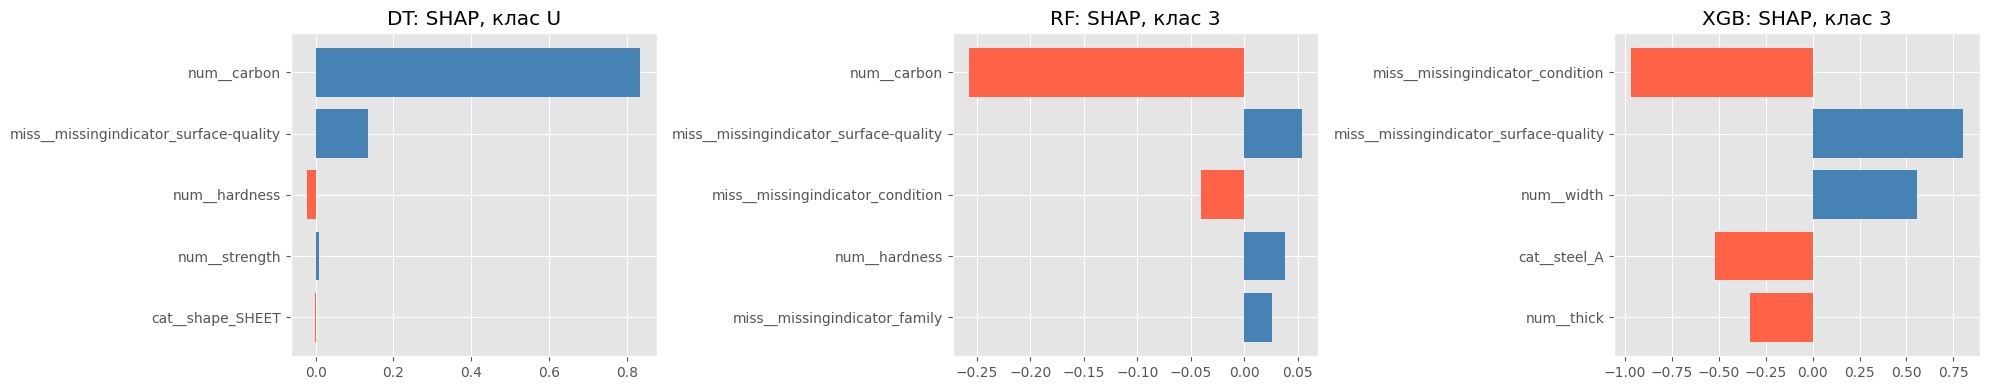

In [23]:
import shap

obj = div.index[0]   # змініть на потрібний (напр., об'єкт класу 1)
x_raw = X_test.loc[[obj]]
row = x_raw.iloc[0]

# 1) Початкові значення, пропуски, імпутація
prep = final_models['XGB'].named_steps['prep']
num_c, cat_c = prep.transformers_[0][2], prep.transformers_[1][2]
fill = dict(zip(num_c, prep.named_transformers_['num'].statistics_))
fill.update(zip(cat_c, prep.named_transformers_['cat'].named_steps['impute'].statistics_))
tab = pd.DataFrame({'початкове': row, 'пропущене': row.isna(),
                    'заповнено значенням': [fill[c] if pd.isna(row[c]) else '' for c in row.index]})
print(f'Об\'єкт #{obj}, справжній клас: {le.classes_[y_test[X_test.index.get_loc(obj)]]}')
display(tab)

# 2) Передбачення й ймовірності
for n, m in final_models.items():
    pr = m.predict_proba(x_raw)[0]
    print(f'{n}: клас {le.classes_[pr.argmax()]}, ймовірності:',
          dict(zip(le.classes_, pr.round(3))))

# 3) SHAP: top-5 внесків у прогнозований клас кожної моделі
def shap_top(model, x_raw, k=5):
    p, c = model.named_steps['prep'], model.named_steps['clf']
    Xt, names = p.transform(x_raw), p.get_feature_names_out()
    sv = shap.TreeExplainer(c).shap_values(Xt)
    sv = np.stack(sv, axis=-1) if isinstance(sv, list) else sv   # (n, f, K)
    cls = int(c.predict(Xt)[0])
    s = pd.Series(sv[0, :, cls], index=names)
    return cls, s.reindex(s.abs().sort_values(ascending=False).index).head(k)

fig, axes = plt.subplots(1, 3, figsize=(20, 4))
for ax, (n, m) in zip(axes, final_models.items()):
    cls, top = shap_top(m, x_raw)
    print(f'\n{n}: прогноз = клас {le.classes_[cls]}'); display(top.round(4))
    ax.barh(top.index[::-1], top.values[::-1],
            color=['tomato' if v < 0 else 'steelblue' for v in top.values[::-1]])
    ax.set_title(f'{n}: SHAP, клас {le.classes_[cls]}')
plt.tight_layout(); plt.show()

Для об'єкта #90 (справжній клас U) вирішальною ознакою виявився carbon = 10: таке значення мають лише два об'єкти всього датасету, обидва класу U. DT виокремлює його одним порогом: внесок carbon у клас U становить 0,834, і об'єкт отримує U з імовірністю 1,0. У RF внесок менший (0,284), бо кожне дерево навчається на bootstrap-вибірці (містить приблизно 63% навчальних об'єктів) і в кожному розбитті бачить лише частину ознак, тому правило відтворюють не всі дерева; ймовірності класів 3 і U становлять 0,573 і 0,42, тобто об'єкт лежить поруч із межею. У XGB внесок carbon у margin класу U (+0,52) не компенсує решту ознак, і модель упевнено (0,946) обирає клас 3; можливе пояснення (гіпотеза, не перевірена): мінімальна вага листка min_child_weight ≈ 1,64 ускладнює виділення листків з одного-двох об'єктів. Крім того, об'єкт нетиповий за патерном пропусків: temper_rolling у нього пропущена, тоді як у класі U вона пропущена лише у 2 із 40 об'єктів; цей індикатор використовує лише XGB (−0,114 для класу U). Внесок імпутованих значень (family→TN, formability→2, bw%2Fme→B) практично нульовий (|SHAP| ≤ 0,002), тому гіпотеза про вплив імпутації для цього об'єкта не підтвердилась. Правильний прогноз DT спирається на єдиний тренувальний об'єкт із carbon = 10, тож це приклад крихкого правила, а не доказ кращої моделі. Значення SHAP для DT і RF подано в ймовірностях, для XGB у log-odds, тому порівнювати слід знаки й порядок ознак, а не величини.

In [24]:
true_cls = int(y_test[X_test.index.get_loc(obj)])

def shap_full(model, x_raw, cls):
    p, c = model.named_steps['prep'], model.named_steps['clf']
    Xt, names = p.transform(x_raw), p.get_feature_names_out()
    sv = shap.TreeExplainer(c).shap_values(Xt)
    sv = np.stack(sv, axis=-1) if isinstance(sv, list) else sv
    return pd.Series(sv[0, :, cls], index=names)

key = ['num__carbon', 'miss__missingindicator_temper_rolling',
       'miss__missingindicator_condition', 'miss__missingindicator_formability',
       'miss__missingindicator_family', 'miss__missingindicator_surface-quality',
       'cat__family_TN', 'cat__formability_2', 'cat__bw%2Fme_B',
       'num__width', 'num__thick']
cmp = pd.DataFrame({n: shap_full(m, x_raw, true_cls)
                    for n, m in final_models.items()}).reindex(key)
print(f'SHAP-внески у справжній клас {le.classes_[true_cls]} (DT/RF — імовірність, XGB — log-odds)')
display(cmp.round(3))

display(pd.crosstab(X['carbon'], y))   # чи характерне carbon=10 для якогось класу
print('train:', (X_train['carbon'] == 10).sum(), '| test:', (X_test['carbon'] == 10).sum())

SHAP-внески у справжній клас U (DT/RF — імовірність, XGB — log-odds)


,DT,RF,XGB
num__carbon,0.834,0.284,0.522
miss__missingindicator_temper_rolling,0.000,0.000,-0.114
miss__missingindicator_condition,0.000,0.045,0.000
miss__missingindicator_formability,0.000,0.004,0.100
miss__missingindicator_family,0.000,0.003,0.000
miss__missingindicator_surface-quality,0.134,0.054,0.019
cat__family_TN,0.000,0.002,0.000
cat__formability_2,0.000,0.000,0.000
cat__bw%2Fme_B,0.000,-0.000,0.000
num__width,0.000,-0.001,-0.117


class,1,2,3,5,U
carbon,,,,,
0,7,99,610,67,38
3,1,0,0,0,0
4,0,0,4,0,0
6,0,0,11,0,0
8,0,0,3,0,0
10,0,0,0,0,2
45,0,0,17,0,0
55,0,0,19,0,0
65,0,0,15,0,0


train: 1 | test: 1


## Висновки

1. За кросвалідацією з типовими параметрами у варіанті B найкращий RF (macro F1 0,967 ± 0,051), але його перевага над XGB (0,964) і DT (0,959) статистично незначуща (Наде–Бенжіо RF vs XGB: p = 0,365), а розкид ≈0,05 однаковий для всіх, переважно через клас 1. 
2. Індикатори пропусків підвищили macro F1 на 0,081 (DT), 0,045 (RF) і 0,070 (XGB), проте значущим за α = 0,05 є лише приріст RF (p = 0,001); для DT (p = 0,064) і XGB (p = 0,095) тест консервативний і не підтверджує значущості. 
3. Це узгоджується з аналізом пропусків (χ²: залежність від класу з p ≤ 0,0013 для 13 з 15 ознак) та важливостями: індикатори становлять 4–7 з 15 найважливіших ознак за MDI, а surface-quality перша за permutation importance в усіх моделей. 
4. best_value перевищує оцінку вкладеної CV на 0,038 (DT), 0,048 (RF) і 0,029 (XGB), тобто звіт про якість за best_value був би оптимістично завищеним. 
5. Оптимізація не дала приросту: порівняно з типовими параметрами на тих самих зовнішніх блоках nested macro F1 знизився на 0,033 (DT), 0,039 (RF) і 0,016 (XGB), імовірно через шумну внутрішню 3-блочну CV, де клас 1 має 2–3 об'єкти. 
6. Найскладніші класи 1 (8 об'єктів, recall 0,50 для XGB на тесті) і U (8 у тесті, recall 0,88): їх плутають із домінуючим класом 3. 
7. На тесті порядок моделей (DT 1,000, RF 0,986, XGB 0,913) протилежний до вкладеної CV, а різницю створюють 1–3 об'єкти. 
8. Усі три об'єкти розбіжностей, де помилився XGB (#90, #406, #827), показують шумність macro F1 при малих класах. 
9. Аналіз об'єкта #90 (справжній U) показав, що DT виокремив його єдиним порогом по carbon = 10, RF опинився на межі (0,573 проти 0,42), а XGB упевнено (0,946) обрав клас 3. 
10. Вплив імпутованих значень цього об'єкта виявився нульовим. 
11. Для практики доцільно обрати RF з індикаторами пропусків і типовими параметрами: найвищий macro F1 у кросвалідації, висока стабільність (std accuracy 0,007), інтерпретованість через permutation importance та помірні витрати (RF вкладена CV ≈324 с проти 141 с в XGB і 10 с у DT), тоді як складніший тюнінг не окупився.

## Відповіді на контрольні питання

**1. Випадковий ліс і одне дерево: зміщення та дисперсія.**
Глибоке дерево має низьке зміщення, але високу дисперсію: невелика зміна даних дає інше дерево. Випадковий ліс усереднює B дерев, навчених на bootstrap-вибірках. Дисперсія усередненого прогнозу дорівнює $\rho\sigma^2 + \frac{1-\rho}{B}\sigma^2$, де $\rho$ – кореляція між деревами. Зміщення майже не змінюється, зменшується лише дисперсія. Збільшення B прибирає тільки другий доданок, а перший залишається, тому важлива декореляція: у кожному розбитті розглядається випадкова підмножина ознак (`max_features`), що зменшує $\rho$. У нашій роботі RF (macro F1 0,967) лише трохи кращий за DT (0,959), а різниця незначуща: при ефекті стелі дисперсія й так мала.

**2. Бустинг і беггінг.**
Беггінг будує незалежні дерева паралельно на bootstrap-вибірках і зменшує дисперсію. Бустинг будує неглибокі дерева послідовно: кожне нове апроксимує градієнт функції втрат (помилки поточного ансамблю), і воно додається з коефіцієнтом `learning_rate`; це переважно зменшує зміщення. До перенавчання зі зростанням кількості дерев схильніший бустинг: кожне наступне дерево підганяється під залишкові помилки, зокрема шум, а похибка на валідації з певного моменту починає зростати. У RF похибка зі збільшенням числа дерев виходить на плато (у наших результатах `n_estimators` має важливість <0,01). Тому в бустингу потрібні `learning_rate`, `subsample`, регуляризація та ранній зупин.

**3. Чому macro F1 і balanced accuracy інформативніші за accuracy.**
При дисбалансі accuracy домінує більшість: клас 3 становить 684 з 898 об'єктів (76%), тож модель, що завжди каже «3», має accuracy ≈0,76 і нульову якість на малих класах. Balanced accuracy – середнє recall по класах, macro F1 – середнє F1 по класах з рівними вагами, тому кожен клас важить однаково, включно з класом 1 (8 об'єктів). Weighted F1 усереднює з вагами за розміром класів, тому великий клас домінує. На нашому тесті для XGB accuracy 0,983 і weighted F1 0,98, а macro F1 лише 0,91, і саме macro F1 показав слабкість на класах 1 і U.

**4. MCAR, MAR, MNAR.**
MCAR: ймовірність пропуску не залежить ні від спостережуваних, ні від неспостережуваних даних. MAR: залежить лише від спостережуваних ознак (наприклад, від класу). MNAR: залежить від самого відсутнього значення або від неспостережуваних чинників. Індикатори пропусків найкорисніші, коли пропуски не MCAR (MAR, MNAR, структурні), бо сам факт пропуску несе інформацію про ціль. За самими даними однозначно відрізнити MAR від MNAR не можна: MNAR залежить від того, чого ми не бачимо, тому потрібні знання предметної області або аналіз чутливості. У нашому датасеті χ²-тест показав залежність пропуску від класу для 13 з 15 ознак, тобто пропуски не схожі на MCAR, а індикатори дали приріст macro F1 (варіант B).

**5. Де виникає витік і як його запобігти.**
Місця витоку: (а) `fit_transform` імпутера або кодувальника на всьому датасеті до поділу чи крос-валідації (медіана й мода «знають» про валідацію); (б) передача в Optuna заздалегідь оброблених даних; (в) використання тестової вибірки в цільовій функції чи для вибору моделі; (г) оцінка якості за `best_value`. Запобігання: імпутація й кодування лише всередині `Pipeline`, у цільову функцію Optuna передається весь пайплайн, оцінка через вкладену CV, тест використовується один раз. У роботі так і зроблено: найкращу модель для матриці плутанини обрано за nested CV, а не за тестом.

**6. Оптимістичність `best_value` і вкладена CV.**
Ми обираємо параметри за максимумом із багатьох зашумлених оцінок на тих самих даних, тому максимум систематично завищений («прокляття переможця»). Вкладена CV: зовнішній цикл ділить дані на блоки, у кожному зовнішньому train запускається внутрішня оптимізація, а якість обчислюється на зовнішньому валідаційному блоці, який в оптимізації не брав участі. Так ми оцінюємо не одну конкретну модель, а **усю процедуру** «підбір гіперпараметрів + навчання» (параметри в різних блоках можуть відрізнятися). У нашій роботі `best_value` перевищує nested-оцінку на 0,038 (DT), 0,048 (RF) і 0,029 (XGB).

**7. Чому парний t-тест не підходить і яку поправку вносить Наде–Бенжіо.**
Блоки крос-валідації перетинаються за тренувальними даними (при 5 блоках будь-які два навчальні набори мають спільні ≈75% об'єктів), а повторення використовують ті самі дані, тож оцінки не є незалежними. Дисперсія середньої різниці занижується, і звичайний t-тест надто легко «знаходить» значущість. Поправка Наде–Бенжіо замінює множник $\frac{1}{kr}$ на $\frac{1}{kr}+\frac{n_{test}}{n_{train}}$; для 5×3 CV це 0,317 замість 0,067 (майже в 4,75 раза), тож t зменшується приблизно в 2,2 раза. Для DT B−A скоригований t = 2,007 (p = 0,064), а звичайний парний t-тест дав би ≈4,4.

**8. MDI і permutation importance.**
MDI – сумарне зменшення неоднорідності від розбиттів по ознаці, обчислене на тренувальних даних для конкретної деревовидної моделі; воно може бути зміщене на користь ознак із багатьма унікальними значеннями і не відображає узагальнення. Permutation importance – падіння метрики після перемішування ознаки на тестових даних; воно не залежить від типу моделі й відображає узагальнення, але дороге й шумне на малій вибірці. Корельовані ознаки: MDI довільно розподіляє важливість між ними, а permutation занижує важливість кожної, бо модель добирає інформацію з «двійника». У нашій роботі це видно на XGB: gain зосереджений на індикаторах `chrom` і `ferro`, а permutation для них ≈0 (Spearman 0,23).

**9. SHAP-значення.**
SHAP – значення Шеплі з теорії кооперативних ігор: внесок ознаки в прогноз як середній маргінальний внесок за всіма можливими коаліціями ознак. Властивість адитивності (local accuracy): базове значення плюс сума SHAP-внесків усіх ознак дорівнює виходу моделі для цього об'єкта (для XGB у log-odds, для дерев sklearn в імовірностях). Локальне пояснення стосується одного прогнозу (у нас об'єкт #90), а глобальна важливість характеризує модель загалом, наприклад середнє |SHAP| за вибіркою, MDI чи permutation importance.

**10. Нативна обробка пропусків у XGBoost (sparsity-aware split finding).**
Для кожного розбиття алгоритм перебирає лише непропущені значення, а об'єкти з пропусками спочатку направляє вліво, потім вправо й обчислює виграш для кожного варіанта. Напрямок із кращим виграшем стає «напрямком за замовчуванням» у вузлі, і так само пропуски обробляються під час прогнозу. Складність лінійна за кількістю непропущених значень. У цій роботі імпутацію застосовано навмисно, щоб усі моделі отримували однакові вхідні дані.

**11. Переваги Optuna над `GridSearchCV` і `RandomizedSearchCV`.**
TPE-семплер будує щільності для «хороших» і «поганих» випробувань і пропонує точки, де їхнє відношення найбільше, тобто використовує історію пошуку, а перебір сітки росте експоненційно з кількістю параметрів, а випадковий пошук нічого не «вчиться». Прунінг достроково зупиняє безперспективні trial, що економить час. Optuna підтримує умовні простори, логарифмічні шкали, цілі й категоріальні параметри та зручну візуалізацію. Проте при шумній цільовій функції будь-який пошук підлаштовується під шум: у нашій роботі при внутрішній 3-блочній CV, де клас 1 має 2–3 об'єкти, оптимізація знизила nested macro F1 порівняно з типовими параметрами.